In [62]:
import yfinance as yf
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.tsa.stattools import coint
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

### Loading the data 

In [63]:
pairs = [
    ("KO", "PEP"),
    ("V", "MA"),
    ("SHEL", "BP"),
]

start = "2016-10-20"
split_date = "2022-10-20"
end = "2026-10-20"  

pair_data = {}

for pair in pairs:
    prices = yf.download(
        list(pair),
        start=start,
        end=end,
        auto_adjust=True,
        progress=False,
    )["Close"]
    print(f"{pair}: missing prices")
    print(prices.isna().sum())
    prices = prices.dropna(how="any")

    pair_data[pair] = {
        "train": prices.loc[prices.index < split_date],
        "test": prices.loc[prices.index >= split_date],
    }


('KO', 'PEP'): missing prices
Ticker
KO     0
PEP    0
dtype: int64
('V', 'MA'): missing prices
Ticker
MA    0
V     0
dtype: int64
('SHEL', 'BP'): missing prices
Ticker
BP      0
SHEL    0
dtype: int64


### EDA

Check the sample sizes and price statistics, then compare the training price paths. Missing prices are reported during loading, before incomplete dates are dropped.


KO-PEP
Train observations: 1510 | Test observations: 1002
Duplicate training dates: 0
Ticker       KO      PEP
count   1510.00  1510.00
mean      41.10   107.17
std        7.32    22.71
min       29.71    73.19
25%       34.86    86.80
50%       39.88   106.99
75%       46.39   121.40
max       58.08   156.53


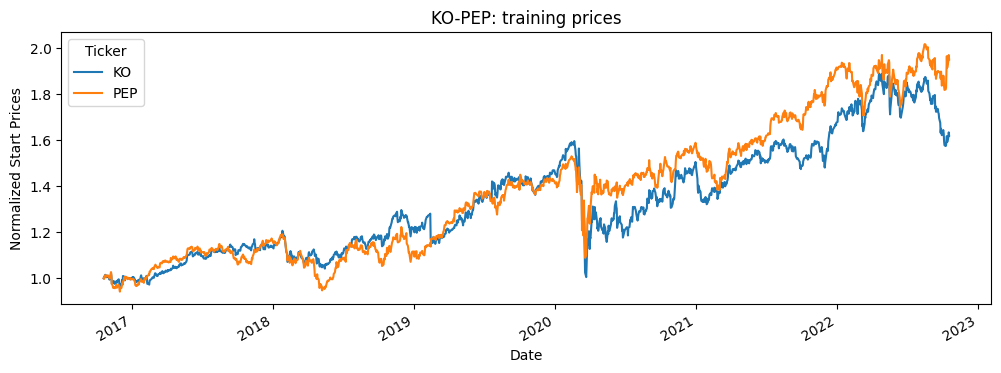

V-MA
Train observations: 1510 | Test observations: 1002
Duplicate training dates: 0
Ticker       MA        V
count   1510.00  1510.00
mean     246.78   158.04
std       87.32    46.52
min       94.49    70.31
25%      171.81   117.43
50%      262.98   168.25
75%      327.18   198.75
max      385.60   240.83


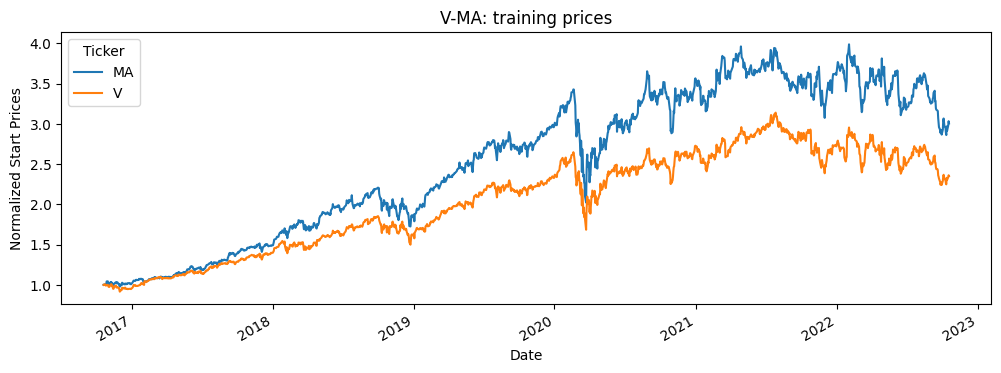

SHEL-BP
Train observations: 1510 | Test observations: 1002
Duplicate training dates: 0
Ticker       BP     SHEL
count   1510.00  1510.00
mean      22.84    38.94
std        4.28     7.73
min       10.96    16.93
25%       20.01    33.41
50%       23.29    41.05
75%       26.30    45.37
max       30.37    52.14


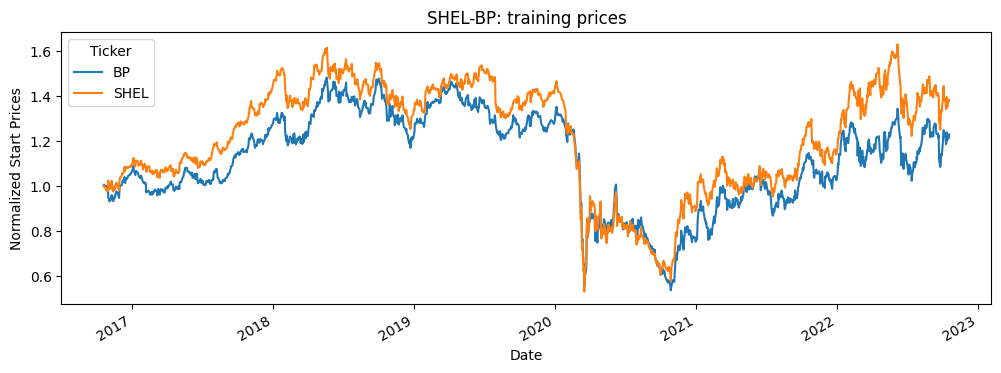

In [64]:
for pair, data in pair_data.items():
    train = data["train"]
    test = data["test"]
    pair_name = f"{pair[0]}-{pair[1]}"

    print(pair_name)
    print("Train observations:", len(train), "| Test observations:", len(test))
    print("Duplicate training dates:", train.index.duplicated().sum())
    print(train.describe().round(2))

    normalized = train / train.iloc[0]
    normalized.plot(figsize=(12, 4), title=f"{pair_name}: training prices")
    plt.ylabel("Normalized Start Prices")
    plt.xlabel("Date")
    plt.show()


## Performing the cointegration test

### 1. Estimating beta using OLS:

**1. Regression model**

$$
P_{A,t} = \alpha + \beta P_{B,t} + \varepsilon_t
$$

**2. Predicted values and residuals**

$$
\hat{P}_{A,t} = \hat{\alpha} + \hat{\beta}P_{B,t}
$$

$$
\hat{\varepsilon}_t = P_{A,t} - \hat{\alpha} - \hat{\beta}P_{B,t}
$$

**3. OLS objective:**

$$
\min_{\alpha,\beta} SSR =
\sum_{t=1}^{T}(P_{A,t}-\alpha-\beta P_{B,t})^2
$$

**4. OLS coefficient estimates**

$$
\hat{\beta} =
\frac{\sum_{t=1}^{T}(P_{B,t}-\bar{P}_B)(P_{A,t}-\bar{P}_A)}
{\sum_{t=1}^{T}(P_{B,t}-\bar{P}_B)^2}
$$

$$
\hat{\alpha} = \bar{P}_A - \hat{\beta}\bar{P}_B
$$

**5. Constructing the spread**

We define the spread as the observed price of A minus its fitted value, so this equals the OLS residuals as calculated in step 2:

$$
S_t = P_{A,t} - \hat{\alpha} - \hat{\beta}P_{B,t} = \hat{\varepsilon}_t.
$$




In [85]:
rows = []
train_spreads = {}

for pair, data in pair_data.items():
    train = data["train"]

    y = train[pair[0]]
    x = train[pair[1]]
    ols = sm.OLS(y, sm.add_constant(x)).fit()
    train_spreads[pair] = ols.resid

    beta = ols.params[pair[1]]
    alpha = ols.params["const"]
    rows.append({
        "pair": f"{pair[0]}-{pair[1]}",
        "alpha": alpha,
        "beta": beta,
    })

pd.DataFrame(rows).set_index("pair")

,alpha,beta
pair,,
KO-PEP,7.823819,0.310495
V-MA,27.204876,0.530148
SHEL-BP,-0.712179,1.736201


## 2. ADF test on the estimated spread

We investigate whether the spread constructed in the previous step is stationary around zero.

$$
S_t = P_{A,t} - \hat{\alpha} - \hat{\beta}P_{B,t}
= \hat{\varepsilon}_t.
$$

### Autoregressive model and first differences

Start with an AR(1) representation of the spread,

$$
S_t = \rho S_{t-1} + u_t.
$$

Here $u_t$ is a random shock. For this AR(1) model, stationarity requires $|\rho|<1$, and a unit root occurs at $\rho=1$.

We rewrite for interpretability: Subtracting $S_{t-1}$ and defining $\gamma=\rho-1$ gives

$$
\Delta S_t = \gamma S_{t-1} + u_t,
\qquad \Delta S_t = S_t-S_{t-1}.
$$

### Augmented regression

Include lagged changes in the spread to account for serial correlation,

$$
\boxed{
\Delta S_t = \gamma S_{t-1}
+ \sum_{i=1}^{k}\phi_i\Delta S_{t-i}
+ u_t.
}
$$

The coefficients $\phi_i$ capture short-run dynamics, and $k$ is the number of lagged differences (we select the lag length by AIC). A negative $\gamma$ indicates adjustment towards zero, subject to stability of the full dynamic model.

### Hypotheses and test statistic

We test the unit-root null against a stationary-spread alternative,

$$
H_0:\gamma=0,
\qquad
H_1:\gamma<0.
$$

Because $S_t$ is constructed using estimated OLS coefficients, it may appear more stationary than it really is. A normal ADF test ignores this estimation step and may falsely detect stationarity.
The Engle–Granger test corrects for this by using special critical values and p-values, making the cointegration test statistically valid. The `coint(y, x, trend="c", autolag="aic")` function performs the first-stage regression and the residual ADF test, selecting the lag length by AIC.

### Decision and interpretation

At the 5% significance level, reject the null of no cointegration when the Engle-Granger p-value is below 0.05. Otherwise, fail to reject the null.

Provided both individual price series are $I(1)$, evidence that the spread is $I(0)$ supports cointegration. Differencing the spread would change the question. Our investigation concerns stationarity of $S_t$ itself.

In [88]:
cointegration_rows = []

for pair, data in pair_data.items():
    train = data["train"]
    statistic, p_value, _ = coint(
        train[pair[0]], train[pair[1]], trend="c", autolag="aic"
    )
    cointegration_rows.append({
        "pair": f"{pair[0]}-{pair[1]}",
        "EG_p_value": p_value,
    })

summary = pd.DataFrame(cointegration_rows).set_index("pair")
summary

,EG_p_value
pair,
KO-PEP,0.161977
V-MA,0.002855
SHEL-BP,0.105939


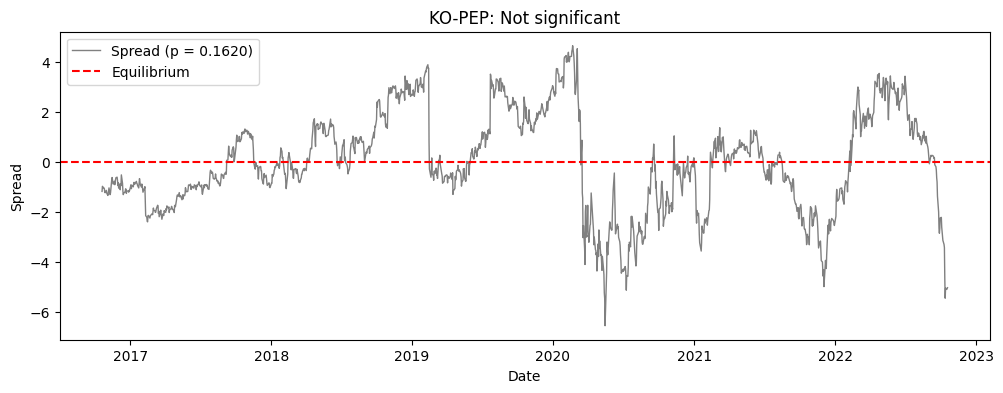

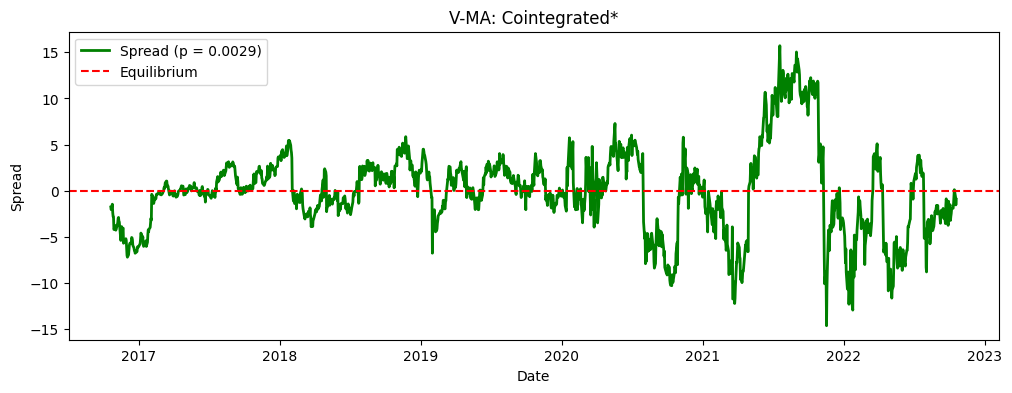

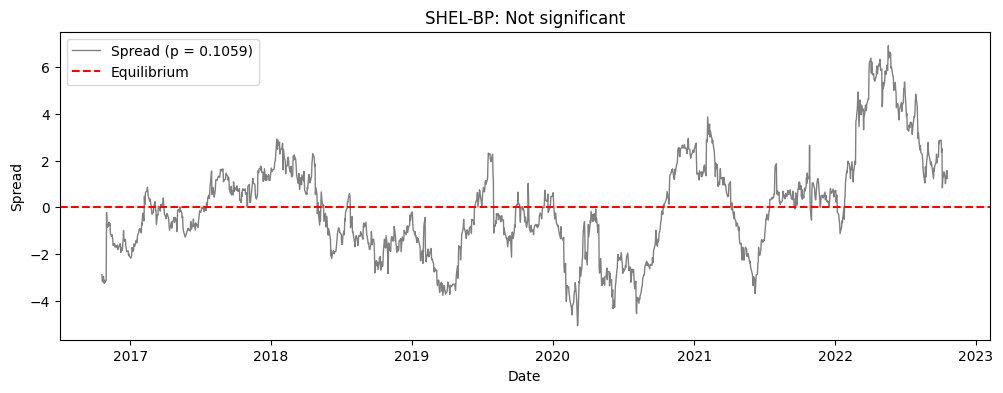

In [89]:
significance_level = 0.05

for pair, spread in train_spreads.items():

    pair_name = f"{pair[0]}-{pair[1]}"
    p_value = summary.loc[pair_name, "EG_p_value"]

    significant = p_value < significance_level

    color = "green" if significant else "grey"
    status = "Cointegrated*" if significant else "Not significant"

    plt.figure(figsize=(12, 4))
    plt.plot(
        spread.index,
        spread,
        color=color,
        linewidth=2 if significant else 1,
        label=f"Spread (p = {p_value:.4f})"
    )

    plt.axhline(0, color="red", linestyle="--", label="Equilibrium")

    plt.title(f"{pair_name}: {status}")
    plt.xlabel("Date")
    plt.ylabel("Spread")
    plt.legend()
    plt.show()

## Half-life of the spread

Now that we've established which pairs exhibit cointegration we calculate the half-life of the spread. For pairs with evidence of cointegration, half-life estimates how many trading days it takes for an expected deviation from equilibrium to shrink by half.

We use the spread already constructed in the training OLS regression,

$$
S_t=P_{A,t}-\hat{\alpha}-\hat{\beta}P_{B,t}.
$$

Fit a simple AR(1) model to this training spread using OLS,

$$
S_t=c+\rho S_{t-1}+u_t,
$$

The coefficient $\rho$ measures how much of a deviation from equilibrium persists into the next trading day. For $0<\rho<1$, values closer to 1 imply slower mean reversion. The model's equilibrium mean is $\mu=c/(1-\rho)$.

With zero-mean future innovations, the expected deviation after $h$ trading days is

$$
\rho^h(S_t-\mu).
$$

The factor $\rho^h$ is the fraction of today's deviation expected to remain after $h$ trading days. Half-life is the time when half remains, so we set this fraction equal to $0.5$. Taking natural logarithms and solving for $h$ gives

$$
\rho^h=0.5
\quad\Longrightarrow\quad
h\ln(\rho)=\ln(0.5)
\quad\Longrightarrow\quad
h=\frac{\ln(0.5)}{\ln(\rho)}.
$$

Substituting the estimated persistence coefficient yields

$$
\boxed{
\hat h_{1/2}
=\frac{\ln(0.5)}{\ln(\hat\rho)}.
}
$$

for $0<\hat\rho<1$. 

A shorter half-life indicates faster mean reversion. With daily observations, half-life is measured in trading days.

In [91]:
half_life_rows = []

for pair, spread in train_spreads.items():
    pair_name = f"{pair[0]}-{pair[1]}"
    if summary.loc[pair_name, "EG_p_value"] >= 0.05:
        continue

    # Regress today's spread on yesterday's spread.
    lagged_spread = spread.shift(1).dropna().rename("lagged_spread")
    model = sm.OLS(
        spread.loc[lagged_spread.index], sm.add_constant(lagged_spread)
    ).fit()
    rho = model.params["lagged_spread"]

    half_life = np.nan
    if 0 < rho < 1:
        half_life = np.log(0.5) / np.log(rho)

    half_life_rows.append({
        "pair": pair_name,
        "rho": rho,
        "half_life_days": half_life,
    })

half_life_summary = pd.DataFrame(
    half_life_rows, columns=["pair", "rho", "half_life_days"]
).set_index("pair")
half_life_summary

,rho,half_life_days
pair,,
V-MA,0.965224,19.582933


### Static and rolling z-scores

The static z-score uses the full training sample:

$$
\boxed{z_t^{\mathrm{static}}=
\frac{S_t-\bar S_{\mathrm{train}}}{s_{\mathrm{train}}}.}
$$

The rolling z-score uses the latest $W$ observations:

$$
\boxed{z_t^{\mathrm{rolling}}=
\frac{S_t-\bar S_{t,W}}{s_{t,W}},
\qquad W=\left\lceil\hat h_{1/2}\right\rceil.}
$$

for $W\geq2$ as

$$
s=\sqrt{\frac{\sum_{i=1}^{W}(S_i-\bar S)^2}{W-1}}
$$

We set $W$ to the estimated half-life rounded up to a whole trading day. 

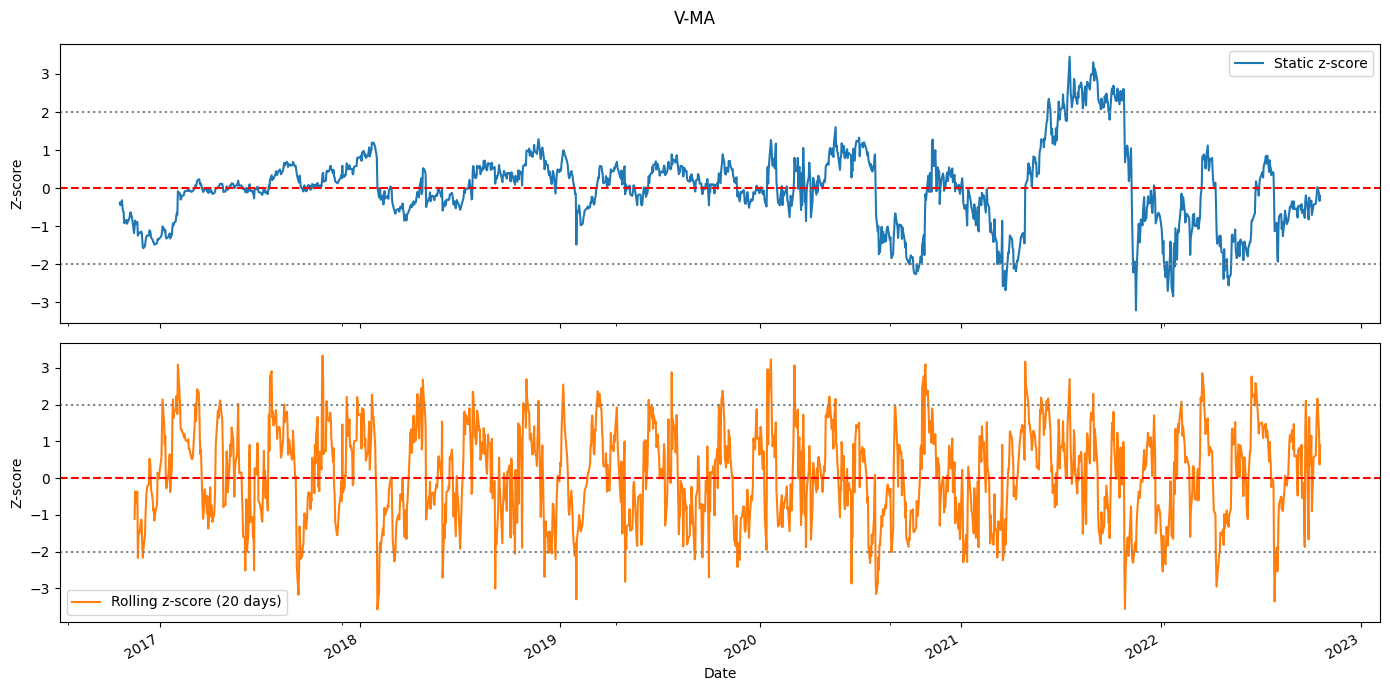

In [93]:
half_lives = pd.DataFrame(
    half_life_rows, columns=["pair", "rho", "half_life_days"]
).set_index("pair")["half_life_days"].dropna()

train_z_scores = {}
train_rolling_z_scores = {}

for pair, spread in train_spreads.items():
    pair_name = f"{pair[0]}-{pair[1]}"
    if pair_name not in half_lives.index:
        continue

    window = int(np.ceil(half_lives[pair_name]))
    rolling = spread.rolling(window)

    static_z = (spread - spread.mean()) / spread.std()
    rolling_z = (spread - rolling.mean()) / rolling.std().replace(0, np.nan)

    train_z_scores[pair] = static_z
    train_rolling_z_scores[pair] = rolling_z

    scores = pd.DataFrame({
        "Static z-score": static_z,
        f"Rolling z-score ({window} days)": rolling_z,
    })
    axes = scores.plot(subplots=True, figsize=(14, 7), title=pair_name)
    for ax in axes:
        ax.axhline(0, color="red", linestyle="--")
        ax.axhline(2, color="grey", linestyle=":")
        ax.axhline(-2, color="grey", linestyle=":")
        ax.set_ylabel("Z-score")
    plt.tight_layout()
    plt.show()

## Trading algorithm

### 1. Prepare test-period z-scores

Construct the test spread as $S_t=P_{A,t}-\hat\alpha-\hat\beta P_{B,t}$.

We calculate both the static z-score and the rolling z-score for the static hedge ratio $\beta $ for the test set.

In [99]:
thresholds = [1.0, 1.5, 2.0, 2.5]
coefficients = pd.DataFrame(rows).set_index("pair")
test_scores = {}

for pair, data in pair_data.items():
    pair_name = f"{pair[0]}-{pair[1]}"
    if pair_name not in half_lives.index:
        continue

    alpha = coefficients.loc[pair_name, "alpha"]
    beta = coefficients.loc[pair_name, "beta"]
    window = int(np.ceil(half_lives[pair_name]))

    prices = pd.concat([data["train"], data["test"]])
    spread = prices[pair[0]] - alpha - beta * prices[pair[1]]
    training_spread = train_spreads[pair]
    rolling = spread.rolling(window)

    scores = pd.DataFrame({
        "spread": spread,
        "static_z": (spread - training_spread.mean()) / training_spread.std(),
        "rolling_z": (spread - rolling.mean()) / rolling.std().replace(0, np.nan),
    })
    test_scores[pair] = scores.loc[data["test"].index]

for pair, scores in test_scores.items():
    print(f"{pair[0]}-{pair[1]}")
    display(scores.head())

V-MA


,spread,static_z,rolling_z
Date,,,
2022-10-20,0.648048,0.142438,2.064656
2022-10-21,0.544662,0.119714,1.762305
2022-10-24,-0.798058,-0.175410,0.592157
2022-10-25,-0.253122,-0.055635,0.946858
2022-10-26,4.216731,0.926820,3.229094


### 2. Generate trading signals

For each pair, z-score type and entry threshold $k\in\{1,1.5,2,2.5\}$.

| Current signal | Condition | New signal |
|---|---|---|
| Flat | $z_t\leq-k$ | $+1$ (long spread) |
| Flat | $z_t\geq k$ | $-1$ (short spread) |
| Long spread | $z_t\geq0$ | $0$ (close) |
| Short spread | $z_t\leq0$ | $0$ (close) |
| Otherwise | | Hold the previous signal |

A long spread represents buying A and selling $\hat\beta$ shares of B per share of A. A short spread reverses these holdings.


In [100]:
trading_signals = {}

for pair, scores in test_scores.items():
    signals = pd.DataFrame(index=scores.index)

    for score_type in ["static_z", "rolling_z"]:
        for threshold in thresholds:
            position = 0
            history = []

            for z in scores[score_type]:
                if pd.notna(z):
                    if position == 0:
                        if z <= -threshold:
                            position = 1
                        elif z >= threshold:
                            position = -1
                    elif (position == 1 and z >= 0) or (position == -1 and z <= 0):
                        position = 0

                history.append(position)

            signals[f"{score_type}_{threshold}"] = history

    trading_signals[pair] = signals

for pair, signals in trading_signals.items():
    print(f"{pair[0]}-{pair[1]}")
    display(signals.head())

V-MA


,static_z_1.0,static_z_1.5,static_z_2.0,static_z_2.5,rolling_z_1.0,rolling_z_1.5,rolling_z_2.0,rolling_z_2.5
Date,,,,,,,,
2022-10-20,0,0,0,0,-1,-1,-1,0
2022-10-21,0,0,0,0,-1,-1,-1,0
2022-10-24,0,0,0,0,-1,-1,-1,0
2022-10-25,0,0,0,0,-1,-1,-1,0
2022-10-26,0,0,0,0,-1,-1,-1,-1


### 3. Execute signals and calculate gross profit

A signal calculated after close $t$ is executed at close $t+1$. The resulting position first earns profit over the interval from close $t+1$ to close $t+2$.

For one share of A hedged with $\hat\beta$ shares of B, let $d_t$ be the position after execution at close $t$. Then

$$
d_t=\text{signal}_{t-1},
\qquad
\mathrm{PnL}_t=d_{t-1}(S_t-S_{t-1}).
$$

The code shifts once to obtain executed positions, then once more to apply the position held during each price change. A positive change in position buys the spread, and a negative change sells it.

Cumulative gross profit is the sum of daily profit. We use adjusted closing prices as execution and valuation proxies, with one fixed spread unit per trade. These results exclude transaction costs, financing and stock-borrow costs. Any final open position is valued at the last available close. Profit is measured in adjusted price units, and comparisons across pairs require capital normalisation.

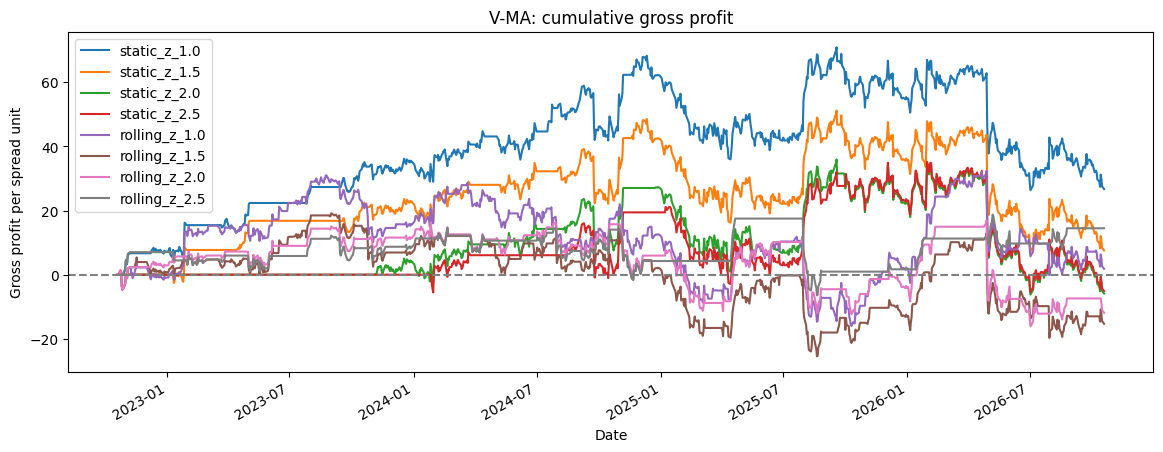

In [101]:
executed_positions = {}
trade_orders = {}
daily_pnl = {}
cumulative_pnl = {}

for pair, signals in trading_signals.items():
    # Today's close executes yesterday's signal.
    positions = signals.shift(1, fill_value=0)
    orders = positions.diff().fillna(positions)

    # Profit belongs to the position held since the previous close.
    spread_change = test_scores[pair]["spread"].diff().fillna(0)
    pnl = positions.shift(1, fill_value=0).mul(spread_change, axis=0)

    executed_positions[pair] = positions
    trade_orders[pair] = orders
    daily_pnl[pair] = pnl
    cumulative_pnl[pair] = pnl.cumsum()

    cumulative_pnl[pair].plot(
        figsize=(14, 5), title=f"{pair[0]}-{pair[1]}: cumulative gross profit"
    )
    plt.ylabel("Gross profit per spread unit")
    plt.xlabel("Date")
    plt.axhline(0, color="grey", linestyle="--")
    plt.show()

### 4. Compare strategies

Compare static and rolling z-scores at each entry threshold. Each completed trade runs from an executed entry to an executed exit. Its gross profit is the direction of the trade multiplied by the change in spread between those closes.

Win rate and average holding time use completed trades. Total gross profit includes the marked-to-market profit of any final open position. Holding time is measured in trading observations. Maximum drawdown measures the largest fall in cumulative gross profit from its previous peak, including the initial zero balance.

All profits and drawdowns are per spread unit. Compare thresholds within each pair using the same position size. Selecting a strategy using this period makes it part of model selection, and an independent performance assessment requires another untouched period.

In [102]:
trades = []
performance_rows = []

for pair, positions in executed_positions.items():
    pair_name = f"{pair[0]}-{pair[1]}"
    spread = test_scores[pair]["spread"]

    for strategy in positions.columns:
        entry = None
        direction = 0
        completed_profits = []
        holding_days = []

        for day, position in enumerate(positions[strategy]):
            if direction == 0 and position != 0:
                entry = day
                direction = position
            elif direction != 0 and position == 0:
                profit = direction * (spread.iloc[day] - spread.iloc[entry])
                duration = day - entry
                completed_profits.append(profit)
                holding_days.append(duration)
                trades.append({
                    "pair": pair_name,
                    "strategy": strategy,
                    "entry": spread.index[entry],
                    "exit": spread.index[day],
                    "direction": direction,
                    "holding_days": duration,
                    "gross_profit": profit,
                })
                direction = 0

        equity = cumulative_pnl[pair][strategy]
        peak = equity.cummax().clip(lower=0)
        performance_rows.append({
            "pair": pair_name,
            "strategy": strategy,
            "gross_profit": daily_pnl[pair][strategy].sum(),
            "completed_trades": len(completed_profits),
            "win_rate": np.mean(np.array(completed_profits) > 0) if completed_profits else np.nan,
            "average_holding_days": np.mean(holding_days) if holding_days else np.nan,
            "max_drawdown": (peak - equity).max(),
            "open_position": direction,
        })

trade_log = pd.DataFrame(trades, columns=[
    "pair", "strategy", "entry", "exit", "direction", "holding_days", "gross_profit"
])
performance = pd.DataFrame(performance_rows, columns=[
    "pair", "strategy", "gross_profit", "completed_trades", "win_rate",
    "average_holding_days", "max_drawdown", "open_position"
]).set_index(["pair", "strategy"])
performance.round(3)

gross_profit  completed_trades  win_rate  \
pair strategy                                                  
V-MA static_z_1.0         26.709                11     1.000   
     static_z_1.5          7.556                 7     1.000   
     static_z_2.0         -5.872                 4     1.000   
     static_z_2.5         -5.117                 3     1.000   
     rolling_z_1.0         1.835                70     0.614   
     rolling_z_1.5       -15.311                53     0.642   
     rolling_z_2.0       -11.892                37     0.622   
     rolling_z_2.5        14.486                22     0.591   

                    average_holding_days  max_drawdown  open_position  
pair strategy                                                          
V-MA static_z_1.0                 48.364        44.586             -1  
     static_z_1.5                 66.286        43.996             -1  
     static_z_2.0                 94.250        42.178             -1  
     static_z_2.5                 91.667        40.667             -1  
     rolling_z_1.0                10.614        46.952             -1  
     rolling_z_1.5                12.075        44.611             -1  
     rolling_z_2.0                13.486        32.999             -1  
     rolling_z_2.5                13.500        23.961              0